# Tennis: player strengths from set scores

A set score such as 7-5 says more than "who won": it says how close the set
was. This notebook gives each player one strength, turns two strengths into
the probability of winning a **point**, follows the scoring system up to the
probability of each **set score**, and fits the strengths to about 6,300 ATP
sets.

The functions used are those of [`docs/examples/tennis.py`](../examples/tennis.py).

## 1. Theory

### Point

Player $i$ wins a point against player $j$ with probability

$$
p_{ij} = \sigma(s_i - s_j) = \frac{1}{1 + e^{-(s_i - s_j)}},
$$

with $s$ the strengths, identified by $\sum_i s_i = 0$. Both players use the
same $p_{ij}$ on every point (no separate serve and return), which keeps one
parameter per player.

### Game and tie-break

A game is won by the first to 4 points with a lead of 2. With $q = 1 - p$,

$$
G(p) = p^4\left(1 + 4q + 10q^2\right) + \binom{6}{3} p^3 q^3 \cdot \frac{p^2}{1 - 2pq},
$$

where the last factor is the probability of winning from deuce (win two points
in a row before losing two). A tie-break is the first to 7 with a lead of 2:

$$
T(p) = \sum_{k=0}^{5} \binom{6+k}{k} p^7 q^k + \binom{12}{6} p^6 q^6 \cdot \frac{p^2}{1-2pq} .
$$

### Set score

With $g = G(p)$ and $t = T(p)$, the probability that $i$ wins the set
$6$–$k$ ($k \le 4$), $7$–$5$ or $7$–$6$ is

$$
\Pr(6\text{–}k) = \binom{5+k}{k} g^6 (1-g)^k, \quad
\Pr(7\text{–}5) = \binom{10}{5} g^5 (1-g)^5\, g^2, \quad
\Pr(7\text{–}6) = \binom{10}{5} g^5 (1-g)^5\, 2 g (1-g)\, t .
$$

`Game`, `TieBreak` and `Set` compute these recursions, with their first and
second derivatives, so the chain rule runs exactly from the set scores back to
the strengths.

### Likelihood

For two players, the 14 outcomes ($i$ wins with one of 7 scores, or $j$ does)
form a distribution. With $N_{ij,k}$ the number of sets $i$ won against $j$
with score $k$,

$$
\ell(s) = \sum_{i \ne j} \sum_k N_{ij,k} \log \Pr{}_{ij}(k) .
$$

### Amplification

A small edge on each point grows into a large edge on a game and a very large
one on a set. That non-linearity is what lets set scores identify point-level
strengths.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2
from maxlike.func import X, Sum, Collapse
from maxlike.func.tennis import Game, TieBreak, Set
import tennis as ex

ps.apply()

point 0.52 -> game 0.550, set 0.640
point 0.55 -> game 0.623, set 0.815


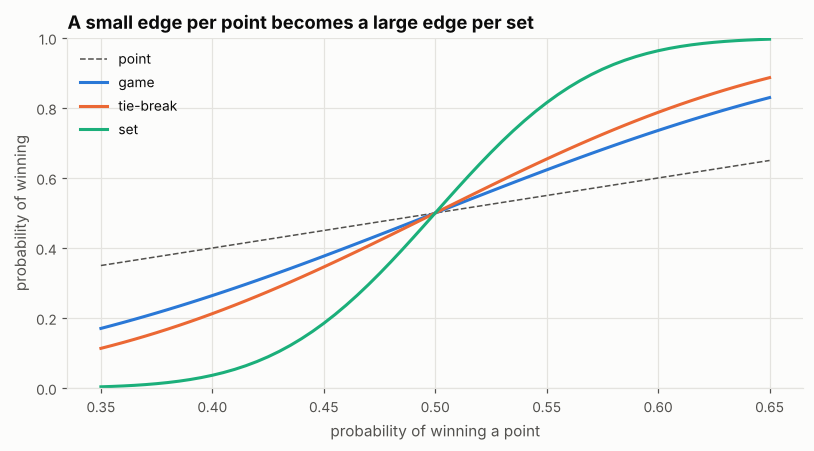

In [2]:
p = np.linspace(0.35, 0.65, 61)
identity = Sum(1)
identity.add(X(), 0, 0)
set_model = Set() @ [Collapse(Game(), False), Collapse(TieBreak(), False)] @ identity
curves = {
    "game": np.asarray(Collapse(Game(), False)([p]).toarray()),
    "tie-break": np.asarray(Collapse(TieBreak(), False)([p]).toarray()),
    "set": np.asarray(Collapse(set_model, False, True)([p]).toarray()),
}

fig, ax = plt.subplots()
ax.plot(p, p, color=TEXT_2, lw=1, ls="--", label="point")
for (label, v), color in zip(curves.items(), [BLUE, ORANGE, AQUA]):
    ax.plot(p, v, color=color, label=label)
ax.set_ylim(0, 1)
ps.finish(ax, "A small edge per point becomes a large edge per set",
          "probability of winning a point", "probability of winning", legend=True)
for q in (0.52, 0.55):
    k = np.argmin(np.abs(p - q))
    print("point %.2f -> game %.3f, set %.3f" % (q, curves["game"][k], curves["set"][k]))

## 2. Data

One row per set: the two players and the games each won.

In [3]:
sets = pd.read_csv(ex.DATA)
N, players = ex.load()
print(len(sets), "sets,", len(players), "players")
sets.head()

6297 sets, 180 players


,player1,player2,score1,score2
0,Dolgopolov O.,Schwartzman D.,6,4
1,De Minaur A.,Johnson S.,7,6
2,Harrison R.,Mayer L.,6,4
3,Ebden M.,Tiafoe F.,6,3
4,Zeballos H.,Escobedo E.,6,3


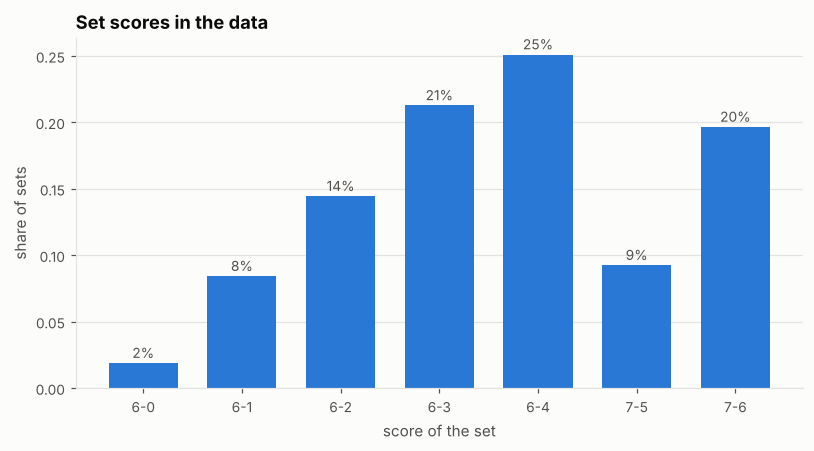

In [4]:
scores = ["%d-%d" % sc for sc in ex.SCORES]
share = N.sum((0, 1)) / N.sum()

fig, ax = plt.subplots()
ax.bar(scores, share, 0.7, color=BLUE)
for k, v in enumerate(share):
    ax.text(k, v + 0.004, "%.0f%%" % (100 * v), ha="center", fontsize=9, color=TEXT_2)
ax.grid(axis="x", visible=False)
ps.finish(ax, "Set scores in the data", "score of the set", "share of sets")

## 3. Model and its graph

The strength difference goes through the logistic function to a point
probability, which feeds both `Game` and `TieBreak`; `Set` combines the two.
`NormalizedFinite` is the multinomial likelihood over the outcomes.

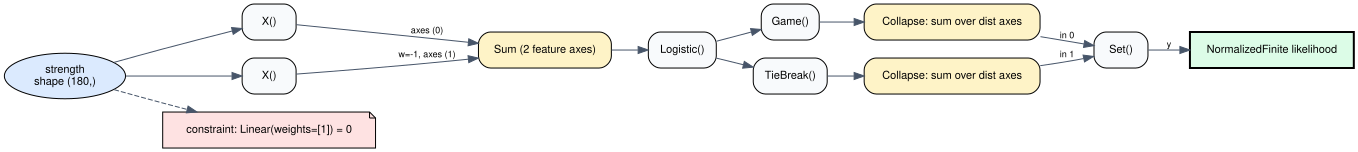

In [5]:
mle = ex.fit(N, players)
mle.graph()

## 4. Strengths

Top 15 players by strength, with 95% intervals. The scale is the log-odds of
winning a point: a gap of 0.1 means about 52.5% of the points between the two
players.

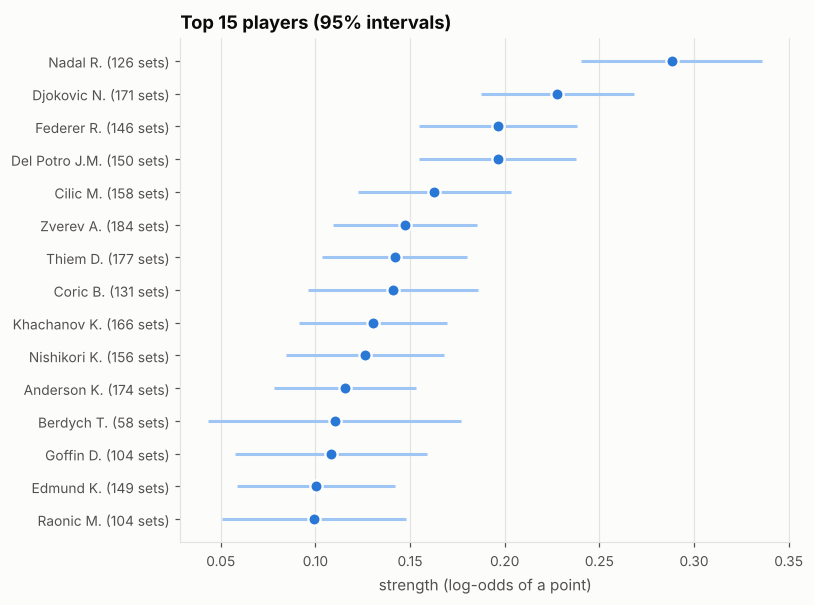

In [6]:
s = mle.summary().loc["strength"].sort_values("estimate", ascending=False)
top = s.head(15).iloc[::-1]
sets_played = pd.Series(N.sum((1, 2)) + N.sum((0, 2)), index=players)

fig, ax = plt.subplots(figsize=(7.5, 5.6))
yy = np.arange(len(top))
ax.errorbar(top["estimate"], yy, xerr=1.96 * top["std_error"], fmt="o", color=BLUE,
            ecolor="#9ec5f4", elinewidth=2, markersize=8, markeredgecolor="#fcfcfb",
            markeredgewidth=1.5)
ax.set_yticks(yy)
ax.set_yticklabels(["%s (%d sets)" % (name, sets_played[name]) for name in top.index])
ax.grid(axis="y", visible=False)
ps.finish(ax, "Top 15 players (95% intervals)", "strength (log-odds of a point)", None)

The intervals are wider for players with fewer sets in the data, as expected.

## 5. Predictions: a head-to-head

The two strongest players: the probability that the first wins a set, with a
delta-method standard error, and the distribution of the 14 possible set
scores.

P(Nadal R. wins a set against Djokovic N.) = 0.606 +/- 0.053


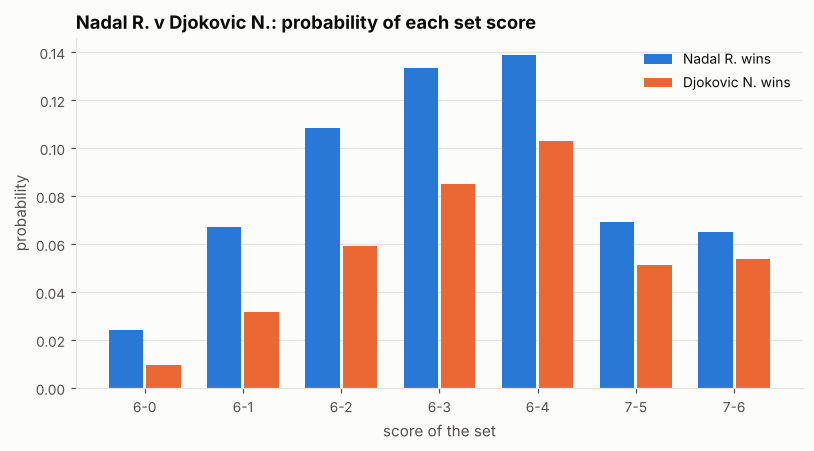

In [7]:
a, b = s.index[0], s.index[1]
i, j = players.index(a), players.index(b)
p_set, se = mle.predict(Collapse(ex.model(), False, True), se=True)
print("P(%s wins a set against %s) = %.3f +/- %.3f" % (a, b, p_set[i, j], se[i, j]))

by_score = mle.predict()
fig, ax = plt.subplots()
xx = np.arange(len(scores))
w = 0.38
ax.bar(xx - w / 2, by_score[i, j], w - 0.03, color=BLUE, label="%s wins" % a)
ax.bar(xx + w / 2, by_score[j, i], w - 0.03, color=ORANGE, label="%s wins" % b)
ax.set_xticks(xx); ax.set_xticklabels(scores)
ax.grid(axis="x", visible=False)
ps.finish(ax, "%s v %s: probability of each set score" % (a, b), "score of the set",
          "probability", legend=True)

## 6. Validation

**Calibration.** For every set in the data, the model gives the probability
that a given one of the two players wins it. The data list the winner first,
so the order of the two players is drawn at random (with a fixed seed). Grouped by that probability, the share
of sets actually won should follow the diagonal.

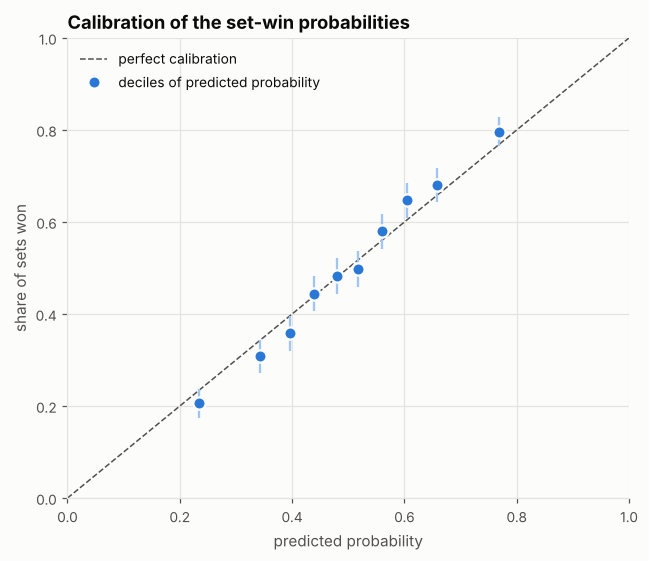

In [8]:
code = {name: k for k, name in enumerate(players)}
w = np.where(sets["score1"] > sets["score2"], sets["player1"], sets["player2"])
l = np.where(sets["score1"] > sets["score2"], sets["player2"], sets["player1"])
winner, loser = pd.Series(w).map(code).values, pd.Series(l).map(code).values
flip = np.random.default_rng(0).random(len(sets)) < 0.5
i1, i2 = np.where(flip, loser, winner), np.where(flip, winner, loser)
pred = p_set[i1, i2]
won = (~flip).astype(float)

bins = pd.qcut(pred, 10, duplicates="drop")
g = pd.DataFrame({"p": pred, "won": won}).groupby(bins, observed=True)
mp, mw, n = g["p"].mean(), g["won"].mean(), g["won"].count()
half = 1.96 * np.sqrt(mw * (1 - mw) / n)

fig, ax = plt.subplots(figsize=(6, 5.2))
ax.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--", label="perfect calibration")
ax.errorbar(mp, mw, yerr=half, fmt="o", color=BLUE, ecolor="#9ec5f4", markersize=8,
            elinewidth=1.5, markeredgecolor="#fcfcfb", markeredgewidth=1.5,
            label="deciles of predicted probability")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ps.finish(ax, "Calibration of the set-win probabilities", "predicted probability",
          "share of sets won", legend=True)

**Score shape.** Given who won, does the model put the right weight on close
and one-sided sets? Summing the model's score probabilities over the sets in
the data gives the expected count of each score, to compare with the observed
counts.

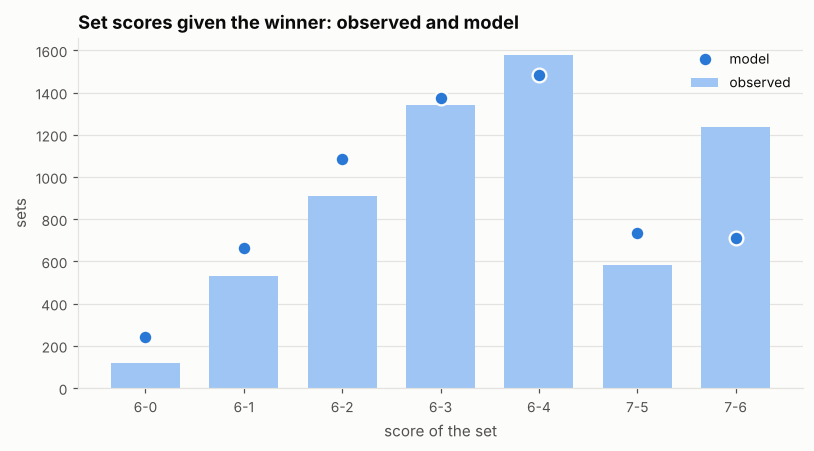

In [9]:
cond = by_score[winner, loser]
cond = cond / cond.sum(-1, keepdims=True)            # score given the winner
observed = N.sum((0, 1))

fig, ax = plt.subplots()
ax.bar(xx, observed, 0.7, color="#9ec5f4", label="observed")
ax.plot(xx, cond.sum(0), "o", color=BLUE, markersize=9, markeredgecolor="#fcfcfb",
        markeredgewidth=1.5, label="model")
ax.set_xticks(xx); ax.set_xticklabels(scores)
ax.grid(axis="x", visible=False)
ps.finish(ax, "Set scores given the winner: observed and model", "score of the set",
          "sets", legend=True)

This check shows the limit of the model. It expects about 700 sets to go to
a tie-break where the data have about 1,240, and too many one-sided sets
(6-0, 6-1, 6-2). Real sets are closer than one point probability per pair
implies, because of the **serve**: each player holds serve far more often than
they win points on return, so games go with serve and sets drift to 6-6. The
natural next step is two strengths per player (serve and return), with the
games of a set alternating between the two point probabilities; the
calibration of who wins, above, is already good without it.